In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
import numpy as np
import pandas as pd

# For reproducible results
np.random.seed(42)

# Number of students
n = 50000

# Create student data
data = pd.DataFrame({
    "CGPA": np.round(np.random.uniform(5.0, 10.0, n), 2),

    "AttendancePercent": np.round(
        np.random.uniform(50, 100, n), 2
    ),

    "Internships": np.random.randint(0, 5, n),

    "Projects": np.random.randint(0, 8, n),

    "Workshops": np.random.randint(0, 10, n),

    "Certifications": np.random.randint(0, 8, n),

    "Publications": np.random.randint(0, 5, n),

    "AptitudeTestScore": np.round(
        np.random.uniform(40, 100, n), 2
    ),

    "SoftSkillsRating": np.round(
        np.random.uniform(1, 10, n), 2
    ),

    "CodingTestScore": np.round(
        np.random.uniform(40, 100, n), 2
    ),

    "MockInterviewScore": np.round(
        np.random.uniform(40, 100, n), 2
    ),

    "ExtraCurricular": np.random.randint(0, 6, n)
})


# ------------------------------------------------
# Create Salary Package
# ------------------------------------------------

# Salary is generated based on student performance
salary = (
    1.5 * data["CGPA"]
    + 0.025 * data["AttendancePercent"]
    + 0.8 * data["Internships"]
    + 0.4 * data["Projects"]
    + 0.15 * data["Workshops"]
    + 0.35 * data["Certifications"]
    + 0.5 * data["Publications"]
    + 0.04 * data["AptitudeTestScore"]
    + 0.25 * data["SoftSkillsRating"]
    + 0.05 * data["CodingTestScore"]
    + 0.04 * data["MockInterviewScore"]
    + 0.2 * data["ExtraCurricular"]
)

# Add some random variation
noise = np.random.normal(0, 1.5, n)

data["Salary Package"] = np.round(
    salary + noise,
    2
)


# ------------------------------------------------
# Add a few missing values
# This allows us to demonstrate missing-value handling
# ------------------------------------------------

for column in [
    "Workshops",
    "Certifications",
    "AptitudeTestScore"
]:
    missing_indices = np.random.choice(
        n,
        size=100,
        replace=False
    )

    data.loc[missing_indices, column] = np.nan


# ------------------------------------------------
# Save dataset as CSV
# ------------------------------------------------

filename = "placement_predict_50k_Dataset.csv"

data.to_csv(
    filename,
    index=False
)

print("Dataset created successfully!")
print("Filename:", filename)
print("Number of rows:", len(data))
print("Number of columns:", len(data.columns))

print("\nFirst 5 rows:")
display(data.head())

Dataset created successfully!
Filename: placement_predict_50k_Dataset.csv
Number of rows: 50000
Number of columns: 13

First 5 rows:


,CGPA,AttendancePercent,Internships,Projects,Workshops,Certifications,Publications,AptitudeTestScore,SoftSkillsRating,CodingTestScore,MockInterviewScore,ExtraCurricular,Salary Package
0,6.87,92.36,1,4,4.0,2.0,2,70.52,7.50,41.28,62.06,1,23.70
1,9.75,74.73,0,3,1.0,4.0,1,92.47,8.80,52.67,69.54,1,30.87
2,8.66,59.77,0,6,4.0,NaN,1,79.30,7.20,56.08,52.59,1,27.44
3,7.99,86.83,0,2,4.0,0.0,1,88.06,1.85,70.62,42.41,5,27.17
4,5.78,70.93,3,7,9.0,0.0,3,77.04,8.25,65.23,73.38,1,28.09


Error: Runtime no longer has a reference to this dataframe, please re-run this cell and try again.


In [ ]:
print("Dataset Shape:")
print(data.shape)

print("\nColumn Names:")
print(data.columns.tolist())

print("\nMissing Values:")
print(data.isnull().sum())

Dataset Shape:
(50000, 13)

Column Names:
['CGPA', 'AttendancePercent', 'Internships', 'Projects', 'Workshops', 'Certifications', 'Publications', 'AptitudeTestScore', 'SoftSkillsRating', 'CodingTestScore', 'MockInterviewScore', 'ExtraCurricular', 'Salary Package']

Missing Values:
CGPA                    0
AttendancePercent       0
Internships             0
Projects                0
Workshops             100
Certifications        100
Publications            0
AptitudeTestScore     100
SoftSkillsRating        0
CodingTestScore         0
MockInterviewScore      0
ExtraCurricular         0
Salary Package          0
dtype: int64


In [ ]:
df = pd.read_csv("placement_predict_50k_Dataset.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (50000, 13)


,CGPA,AttendancePercent,Internships,Projects,Workshops,Certifications,Publications,AptitudeTestScore,SoftSkillsRating,CodingTestScore,MockInterviewScore,ExtraCurricular,Salary Package
0,6.87,92.36,1,4,4.0,2.0,2,70.52,7.50,41.28,62.06,1,23.70
1,9.75,74.73,0,3,1.0,4.0,1,92.47,8.80,52.67,69.54,1,30.87
2,8.66,59.77,0,6,4.0,NaN,1,79.30,7.20,56.08,52.59,1,27.44
3,7.99,86.83,0,2,4.0,0.0,1,88.06,1.85,70.62,42.41,5,27.17
4,5.78,70.93,3,7,9.0,0.0,3,77.04,8.25,65.23,73.38,1,28.09


In [ ]:
FEATURES = [
    "CGPA",
    "AttendancePercent",
    "Internships",
    "Projects",
    "Workshops",
    "Certifications",
    "Publications",
    "AptitudeTestScore",
    "SoftSkillsRating",
    "CodingTestScore",
    "MockInterviewScore",
    "ExtraCurricular"
]

TARGET = "Salary Package"

data = df[FEATURES + [TARGET]].copy()

print("Features selected:")
print(FEATURES)

print("\nTarget:")
print(TARGET)

print("\nData shape:")
print(data.shape)

Features selected:
['CGPA', 'AttendancePercent', 'Internships', 'Projects', 'Workshops', 'Certifications', 'Publications', 'AptitudeTestScore', 'SoftSkillsRating', 'CodingTestScore', 'MockInterviewScore', 'ExtraCurricular']

Target:
Salary Package

Data shape:
(50000, 13)


In [ ]:
 print("Missing values before handling:")

print(data.isnull().sum())

# Fill missing feature values with median
data[FEATURES] = data[FEATURES].fillna(
    data[FEATURES].median()
)

# Remove rows if target has missing values
data = data.dropna(subset=[TARGET])

print("\nMissing values after handling:")

print(data.isnull().sum())

print("\nFinal data shape:")
print(data.shape)

Missing values before handling:
CGPA                    0
AttendancePercent       0
Internships             0
Projects                0
Workshops             100
Certifications        100
Publications            0
AptitudeTestScore     100
SoftSkillsRating        0
CodingTestScore         0
MockInterviewScore      0
ExtraCurricular         0
Salary Package          0
dtype: int64

Missing values after handling:
CGPA                  0
AttendancePercent     0
Internships           0
Projects              0
Workshops             0
Certifications        0
Publications          0
AptitudeTestScore     0
SoftSkillsRating      0
CodingTestScore       0
MockInterviewScore    0
ExtraCurricular       0
Salary Package        0
dtype: int64

Final data shape:
(50000, 13)


In [ ]:
print("Missing values before handling:")

print(data.isnull().sum())

# Fill missing feature values with median
data[FEATURES] = data[FEATURES].fillna(
    data[FEATURES].median()
)

# Remove rows if target has missing values
data = data.dropna(subset=[TARGET])

print("\nMissing values after handling:")

print(data.isnull().sum())

print("\nFinal data shape:")
print(data.shape)

Missing values before handling:
CGPA                  0
AttendancePercent     0
Internships           0
Projects              0
Workshops             0
Certifications        0
Publications          0
AptitudeTestScore     0
SoftSkillsRating      0
CodingTestScore       0
MockInterviewScore    0
ExtraCurricular       0
Salary Package        0
dtype: int64

Missing values after handling:
CGPA                  0
AttendancePercent     0
Internships           0
Projects              0
Workshops             0
Certifications        0
Publications          0
AptitudeTestScore     0
SoftSkillsRating      0
CodingTestScore       0
MockInterviewScore    0
ExtraCurricular       0
Salary Package        0
dtype: int64

Final data shape:
(50000, 13)


In [ ]:
X = data[FEATURES].values

y = data[TARGET].values.reshape(-1, 1)

print("X shape:", X.shape)

print("y shape:", y.shape)

X shape: (50000, 12)
y shape: (50000, 1)


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training data shape:")
print(X_train.shape)

print("\nTesting data shape:")
print(X_test.shape)


# Standardization
scaler = StandardScaler()

X_train_s = scaler.fit_transform(X_train)

X_test_s = scaler.transform(X_test)

print("\nScaling completed!")

Training data shape:
(40000, 12)

Testing data shape:
(10000, 12)

Scaling completed!


In [ ]:
n_samples, n_features = X_train_s.shape

# Add bias column
X_train_b = np.hstack([
    np.ones((n_samples, 1)),
    X_train_s
])

X_test_b = np.hstack([
    np.ones((X_test_s.shape[0], 1)),
    X_test_s
])

print("Training matrix with bias:")
print(X_train_b.shape)

print("\nTesting matrix with bias:")
print(X_test_b.shape)

Training matrix with bias:
(40000, 13)

Testing matrix with bias:
(10000, 13)


In [ ]:
def compute_mse(X, y, theta):

    predictions = X @ theta

    errors = predictions - y

    mse = np.mean(errors ** 2)

    return mse


print("MSE function created successfully!")

MSE function created successfully!


In [ ]:
def batch_gradient_descent(
    X,
    y,
    lr=0.05,
    n_epochs=500
):

    m, n = X.shape

    # Initialize weights
    theta = np.zeros((n, 1))

    # Store loss values
    loss_history = []

    # Training loop
    for epoch in range(n_epochs):

        # Predictions
        predictions = X @ theta

        # Calculate errors
        errors = predictions - y

        # Calculate gradient
        gradient = (2 / m) * (X.T @ errors)

        # Update weights
        theta = theta - lr * gradient

        # Calculate MSE
        loss = compute_mse(X, y, theta)

        loss_history.append(loss)

    return theta, loss_history


print("Batch Gradient Descent function created!")

Batch Gradient Descent function created!


In [ ]:
theta_gd, loss_history_gd = batch_gradient_descent(
    X_train_b,
    y_train,
    lr=0.05,
    n_epochs=500
)

print("Batch Gradient Descent training completed!")

Batch Gradient Descent training completed!


In [ ]:
rmse_gd = np.sqrt(
    compute_mse(
        X_test_b,
        y_test,
        theta_gd
    )
)

print("Batch Gradient Descent Test RMSE:")

print(f"{rmse_gd:.4f}")

Batch Gradient Descent Test RMSE:
1.4944


In [ ]:
sk_model = LinearRegression()

sk_model.fit(
    X_train_s,
    y_train
)

print("sklearn Linear Regression training completed!")

sklearn Linear Regression training completed!


In [ ]:
y_pred_sk = sk_model.predict(X_test_s)

rmse_sklearn = np.sqrt(
    mean_squared_error(
        y_test,
        y_pred_sk
    )
)

print("sklearn Linear Regression Test RMSE:")

print(f"{rmse_sklearn:.4f}")

print("\nDifference between Batch GD and sklearn:")

print(f"{rmse_gd - rmse_sklearn:.6f}")

sklearn Linear Regression Test RMSE:
1.4944

Difference between Batch GD and sklearn:
0.000000


In [ ]:
def mini_batch_gradient_descent(
    X,
    y,
    lr=0.05,
    n_epochs=500,
    batch_size=256,
    seed=42
):

    m, n = X.shape

    # Initialize weights
    theta = np.zeros((n, 1))

    # Store loss
    loss_history = []

    # Random number generator
    rng = np.random.default_rng(seed)

    # Epoch loop
    for epoch in range(n_epochs):

        # Shuffle data
        indices = rng.permutation(m)

        X_shuffled = X[indices]
        y_shuffled = y[indices]

        # Process mini-batches
        for start in range(0, m, batch_size):

            end = start + batch_size

            X_batch = X_shuffled[start:end]
            y_batch = y_shuffled[start:end]

            # Predictions
            predictions = X_batch @ theta

            # Errors
            errors = predictions - y_batch

            # Gradient
            gradient = (
                2 / X_batch.shape[0]
            ) * (X_batch.T @ errors)

            # Update weights
            theta = theta - lr * gradient

        # Calculate full training MSE
        loss = compute_mse(X, y, theta)

        loss_history.append(loss)

    return theta, loss_history


print("Mini-Batch Gradient Descent function created!")

Mini-Batch Gradient Descent function created!


In [ ]:
theta_mb, loss_history_mb = mini_batch_gradient_descent(
    X_train_b,
    y_train,
    lr=0.05,
    n_epochs=500,
    batch_size=256,
    seed=42
)

print("Mini-Batch Gradient Descent training completed!")

Mini-Batch Gradient Descent training completed!


In [ ]:
rmse_mb = np.sqrt(
    compute_mse(
        X_test_b,
        y_test,
        theta_mb
    )
)

print("Mini-Batch Gradient Descent Test RMSE:")

print(f"{rmse_mb:.4f}")

Mini-Batch Gradient Descent Test RMSE:
1.4966


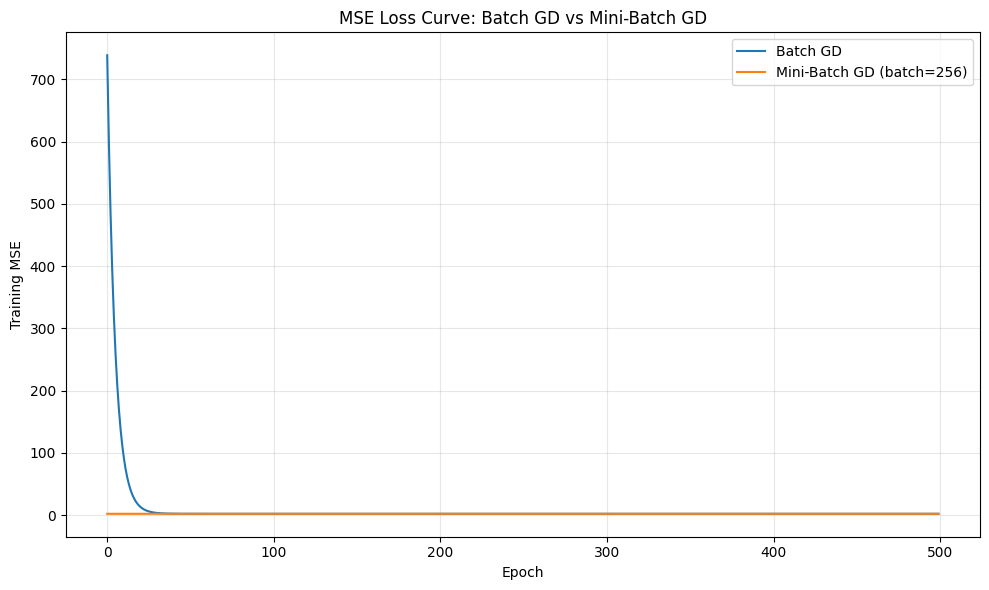

In [ ]:
plt.figure(figsize=(10, 6))

plt.plot(
    loss_history_gd,
    label="Batch GD"
)

plt.plot(
    loss_history_mb,
    label="Mini-Batch GD (batch=256)"
)

plt.xlabel("Epoch")

plt.ylabel("Training MSE")

plt.title(
    "MSE Loss Curve: Batch GD vs Mini-Batch GD"
)

plt.legend()

plt.grid(alpha=0.3)

plt.tight_layout()

plt.show()

In [ ]:
results = pd.DataFrame({
    "Method": [
        "Batch Gradient Descent",
        "Mini-Batch Gradient Descent",
        "sklearn Linear Regression"
    ],

    "Test RMSE": [
        rmse_gd,
        rmse_mb,
        rmse_sklearn
    ]
})

print("========== RMSE COMPARISON ==========")

display(results)

========== RMSE COMPARISON ==========


,Method,Test RMSE
0,Batch Gradient Descent,1.494386
1,Mini-Batch Gradient Descent,1.496648
2,sklearn Linear Regression,1.494386


In [ ]:
print("==========================================")
print("       EXPERIMENT 3 - FINAL RESULTS")
print("==========================================")

print(f"Batch GD RMSE          : {rmse_gd:.4f}")

print(f"Mini-Batch GD RMSE     : {rmse_mb:.4f}")

print(f"sklearn Linear Reg RMSE: {rmse_sklearn:.4f}")

print("------------------------------------------")

print(
    f"GD - sklearn Difference : "
    f"{rmse_gd - rmse_sklearn:.6f}"
)

print("==========================================")
print("       EXPERIMENT COMPLETED")
print("==========================================")

       EXPERIMENT 3 - FINAL RESULTS
Batch GD RMSE          : 1.4944
Mini-Batch GD RMSE     : 1.4966
sklearn Linear Reg RMSE: 1.4944
------------------------------------------
GD - sklearn Difference : 0.000000
       EXPERIMENT COMPLETED
